# Cell-to-tissue similarity: do chemical signatures resemble tumour deregulation?

The core analysis of the study. A compound's transcriptional response in MCF7
(LINCS L1000) is compared with the deregulation measured between TCGA-BRCA
tumours and GTEx normal breast tissue, by cosine similarity on the genes that
are deregulated in the tissue.

Three comparisons, in order:

| Section | Comparison | Output |
|---|---|---|
| 4 | each compound signature vs the **pooled** tumour signature | Figure 6, Tables S15-S16 |
| 5 | each compound signature vs **each of the 1,092 tumours** | Figure 5, Table S14 |
| 6 | **MC vs SMC** compound signatures | Figure 3, Table S11 |

**Naming**: `MC` = mammary carcinogens, `SMC` = suspected mammary carcinogens.
`L` = the 978 landmark genes, `LBI` = landmark + best-inferred genes.

In [1]:
import glob
import os
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pubchempy as pcp
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

sys.path.insert(0, "..")
from common import flatten, simulate_null_cosine

TABLES = "../../results/tables/cosine_similarity"
FIGURES = "../../figures"
DATA = "../../data/external"

P_CUTOFF = 0.05        # raw p-value filter on the tissue differential expression
Z_CUTOFFS = (1, 2)     # |z| thresholds defining the tissue reference signature
K_EMPIRICAL = 3.595    # from 01_similarity_threshold.ipynb
FLATTEN_CUTOFF = 2     # |z| below which a compound value is set to 0 (section 6)
PAIR_CUTOFF = 0.4      # minimum similarity to keep a profile in Figure 3

## 1. Genes shared between the two measurements

Only genes present in both the L1000 feature space and the tissue
differential expression can be compared, so the gene set is intersected first
and kept in two versions — landmark only, and landmark + best inferred.

In [2]:
gene_info = pd.read_csv("../../data/lincs-metadata/geneinfo_beta.txt", sep="\t")
feature_spaces = {
    "L": gene_info[gene_info["feature_space"] == "landmark"],
    "LBI": gene_info[gene_info["feature_space"].isin(["landmark", "best inferred"])],
}
symbol_to_id = {
    space: dict(zip(info["gene_symbol"], info["gene_id"]))
    for space, info in feature_spaces.items()
}

In [3]:
def tissue_signature(path):
    """Significant tissue DEGs, indexed by gene symbol, per feature space.

    Returns one frame per feature space with the L1000 numeric gene id and the
    z-score of the logFC.
    """
    degs = pd.read_csv(path, index_col=0)
    degs = degs[degs["PValue"] < P_CUTOFF]

    signatures = {}
    for space, info in feature_spaces.items():
        sig = degs[degs["gene"].isin(info["gene_symbol"])].copy()
        sig["gene"] = sig["gene"].map(symbol_to_id[space])
        signatures[space] = sig[["gene", "z_score"]]
    return signatures


tissue = tissue_signature(f"{DATA}/DGEA_TCGA_GTEX/DGEA_edgeR_QLF_all.csv")
for space, sig in tissue.items():
    print(f"{space:3s}: {len(sig)} genes shared with the tissue signature")

L  : 888 genes shared with the tissue signature
LBI: 8833 genes shared with the tissue signature


## 2. Compound signatures

MCF7 signatures at 24 h, one per compound-dose condition (best TAS replicate),
split into the two compound classes.

In [4]:
mc_compounds = pd.read_csv("../../data/chemicals/Merged_MC_chemlist.csv")
all_compounds = pd.read_csv("../../data/chemicals/Chemicals_concat.csv")
smc_compounds = all_compounds[all_compounds["Chem_type"] == "SMC"]

l1000 = pd.read_csv(f"{DATA}/L1000/L1000_MCF7_l_bi_bestTAS.csv")
l1000 = l1000[l1000["time"] == "24 h"]

signatures = {
    "MC": l1000[l1000["inchikey"].isin(mc_compounds["INCHIKEY"])],
    "SMC": l1000[l1000["inchikey"].isin(smc_compounds["INCHIKEY"])],
}
# Columns 0-6 are metadata (sig_id, brd_id, inchikey, dose, time, cell, allcond).
zscores = {name: df.iloc[:, 7:] for name, df in signatures.items()}

for name, df in signatures.items():
    print(f"{name:3s}: {len(df)} signatures, {df['inchikey'].nunique()} compounds")

MC : 220 signatures, 34 compounds
SMC: 840 signatures, 127 compounds


## 3. Empirical similarity threshold

Cosine similarity between two random profiles is not centred on zero in a
useful way: its spread depends on the number of genes compared, so a single
flat cut-off would be stricter for long signatures than for short ones. The
threshold is therefore calibrated per signature length against a null
distribution of random profiles:

$Th(N) = \mu_N + k \cdot \sigma_N$

where $\mu_N$ and $\sigma_N$ are the mean and standard deviation of the cosine
similarity between pairs of random normal profiles of $N$ genes, and
$k = 3.595$ is the empirical constant derived in `01_similarity_threshold.ipynb`.

In [5]:
def similarity_threshold(n_genes, k=K_EMPIRICAL):
    mu, sigma = simulate_null_cosine(n_genes)
    return mu + k * sigma


thresholds = {}
for space, sig in tissue.items():
    for cutoff in Z_CUTOFFS:
        n_genes = (sig["z_score"].abs() > cutoff).sum()
        thresholds[(space, cutoff)] = similarity_threshold(n_genes)
        print(f"{space:3s} |z|>{cutoff}: {n_genes:5d} genes, "
              f"threshold {thresholds[(space, cutoff)]:.4f}")

L   |z|>1:   139 genes, threshold 0.3047
L   |z|>2:    27 genes, threshold 0.6917


LBI |z|>1:  1812 genes, threshold 0.0843


LBI |z|>2:   410 genes, threshold 0.1775


## 4. Compound signatures vs the pooled tumour signature

Figure 6 and Supplementary Tables S15-S16.

In [6]:
def compound_similarity(chem_class, space, cutoff, reference=None):
    """Cosine similarity of every signature of a class to a tissue signature.

    `reference` defaults to the pooled tissue signature; section 5 passes a
    single-tumour signature instead.
    """
    sig = (reference or tissue)[space]
    sig = sig[sig["z_score"].abs() > cutoff]
    genes = [str(g) for g in sig["gene"]]
    profiles = zscores[chem_class].loc[:, genes]
    values = cosine_similarity(sig["z_score"].values.reshape(1, -1), profiles)[0]
    return pd.Series(values, index=signatures[chem_class]["sig_id"].values)


similarity = {
    (chem_class, space): pd.DataFrame(
        {cutoff: compound_similarity(chem_class, space, cutoff) for cutoff in Z_CUTOFFS}
    ).sort_values(max(Z_CUTOFFS))
    for chem_class in ("MC", "SMC")
    for space in ("L", "LBI")
}

In [7]:
# Compound names are resolved once and **versioned** in the repository. They are
# not re-fetched on every run, because PubChem reorders its synonym lists over
# time: `synonyms[0]` today returns the CAS number for ibuprofen (58560-75-1)
# and for equol (531-95-3), where it returned the common name when the article
# was prepared. A figure whose axis labels depend on a live database is not
# reproducible, so the lookup is frozen here and PubChem is only queried for
# InChIKeys the table does not already cover.
NAME_CACHE = "../../data/chemicals/compound_names.csv"

# PubChem holds these two compounds but returns no synonym at all for them, so
# an automatic lookup cannot name them. Identities checked against the PubChem
# compound record:
#   BNRNXUUZRGQAQC-UHFFFAOYSA-N  C22H30N6O4S, MW 474.6, CID 5212  -> sildenafil
#   KNAHARQHSZJURB-UHFFFAOYSA-N  C7H10N2OS, MW 170.23, CID 657298, PubChem
#                                title "Propylthiouracil"
MANUAL_NAMES = {
    "BNRNXUUZRGQAQC-UHFFFAOYSA-N": "sildenafil",
    "KNAHARQHSZJURB-UHFFFAOYSA-N": "propylthiouracil",
}

# Long names are abbreviated **on the figure axes only**; the result tables keep
# the full name. Nordihydroguaiaretic acid is spelled two ways across sources,
# so both are mapped.
ABBREVIATIONS = {
    "medroxyprogesterone acetate": "MPA",
    "cyclophosphamide": "CP",
    "tert-butylhydroquinone": "tBHQ",
    "nordihydroguaiaretic acid": "NDGA",
    "nordihydroguaretic acid": "NDGA",
}

CAS_PATTERN = re.compile(r"^\d{2,7}-\d{2}-\d$")


def compound_names(inchikeys):
    """InChIKey -> lower-case common name, from the versioned lookup table."""
    cache = (
        pd.read_csv(NAME_CACHE, index_col=0)["compound_name"].to_dict()
        if os.path.exists(NAME_CACHE)
        else {}
    )
    # The verified names take precedence over the table, so that a compound
    # PubChem cannot name is always labelled from its checked identity rather
    # than from whatever a previous run happened to store.
    cache.update(MANUAL_NAMES)

    unresolved = []
    for key in set(inchikeys) - set(cache):
        try:
            compound = pcp.get_compounds(key, "inchikey")[0]
            synonyms = compound.synonyms or []
            # Skip CAS registry numbers: they head some synonym lists but are
            # useless as an axis label.
            named = [s for s in synonyms if not CAS_PATTERN.match(s)]
            cache[key] = (named or synonyms or [compound.iupac_name])[0].lower()
        except Exception:  # unknown key, no name at all, or PubChem unreachable
            cache[key] = key          # never guess: fall back to the identifier
            unresolved.append(key)

    if unresolved:
        print(f"⚠️ {len(unresolved)} InChIKeys unresolved, labelled by identifier:")
        print("\n".join(f"   {k}" for k in unresolved))

    pd.Series(cache, name="compound_name").rename_axis("inchikey").to_csv(NAME_CACHE)
    return cache


def axis_name(names, inchikey):
    """Figure-axis label for a compound: abbreviated when it is a long name."""
    name = names[inchikey]
    return ABBREVIATIONS.get(name, name)


def condition_labels(chem_class, names, width=25):
    """'compound   dose   time' label per signature, for figure axes."""
    df = signatures[chem_class]
    return [
        f"{axis_name(names, row.inchikey): <{width}}  {row.dose: <8}  {row.time}"
        for row in df.itertuples()
    ]


# Only the compounds of the two classes are resolved: the full 24 h file holds
# 12,352 compounds, and the PubChem API allows 5 requests per second.
needed = pd.concat([signatures["MC"], signatures["SMC"]])["inchikey"].unique()
names = compound_names(needed)

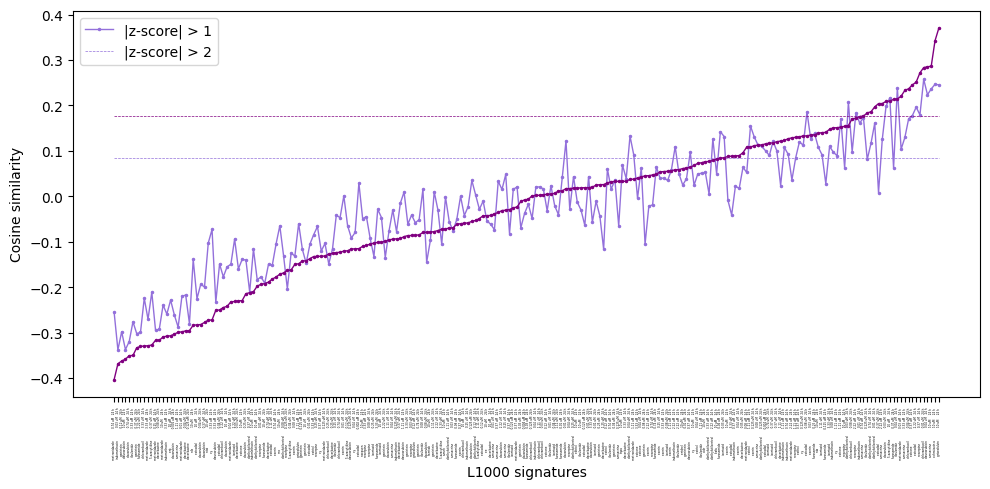

In [8]:
def plot_similarity(table, space, labels, filename=None):
    """Similarity of each signature at both z-cutoffs, with the thresholds."""
    fig, ax = plt.subplots(figsize=(10, 5))
    colors = {1: "mediumpurple", 2: "purple"}
    for cutoff in Z_CUTOFFS:
        ax.plot(labels, table[cutoff], "o-", color=colors[cutoff],
                linewidth=1, markersize=1.5)
        ax.hlines(thresholds[(space, cutoff)], 0, len(labels) - 1,
                  color=colors[cutoff], linestyle="--", linewidth=0.5)

    ax.set_xlabel("L1000 signatures")
    ax.set_ylabel("Cosine similarity")
    ax.legend([f"|z-score| > {c}" for c in Z_CUTOFFS])
    plt.xticks(rotation="vertical", size=2)
    plt.tight_layout()
    if filename:
        for ext in ("png", "pdf"):
            fig.savefig(f"{FIGURES}/{filename}.{ext}", dpi=500, bbox_inches="tight")
    # The preview below is deliberately low-resolution; the signature labels are
    # only legible in the saved file.
    plt.show()


table = similarity[("MC", "LBI")]
labels = pd.Series(
    condition_labels("MC", names), index=signatures["MC"]["sig_id"].values
).reindex(table.index)
plot_similarity(table, "LBI", labels.tolist(),
                "Figure-6_MC_Compounds_lbi_genes_cossim_3")

In [9]:
# Tables S15-S16: signatures above the threshold at both z-cutoffs.
for chem_class, filename in (("MC", "Table_MC_CS_Analysis_Sim_Only.csv"),
                             ("SMC", "Table_SMC_CS_Analysis_Sim_Only.csv")):
    table = similarity[(chem_class, "LBI")]
    above = table[
        (table[1] > thresholds[("LBI", 1)]) & (table[2] > thresholds[("LBI", 2)])
    ]
    selected = (
        signatures[chem_class][["sig_id", "inchikey", "dose", "time"]]
        .merge(above.rename(columns={1: "z_score_cut_1", 2: "z_score_cut_2"}),
               left_on="sig_id", right_index=True)
        .sort_values("z_score_cut_2", ascending=False)
    )
    selected.insert(2, "compound_name", [names[k] for k in selected["inchikey"]])
    selected.to_csv(f"{TABLES}/{filename}", index=False)
    print(f"{chem_class:3s}: {len(selected)} signatures above threshold, "
          f"{selected['inchikey'].nunique()} compounds -> {filename}")

MC : 17 signatures above threshold, 13 compounds -> Table_MC_CS_Analysis_Sim_Only.csv
SMC: 70 signatures above threshold, 48 compounds -> Table_SMC_CS_Analysis_Sim_Only.csv


## 5. Compound signatures vs each tumour

The pooled comparison above averages over patients. Repeating it against the
1,092 per-tumour signatures (`DGEA_analysis_indiv.Rmd`) shows how much the
similarity varies between patients — Figure 5 and Supplementary Table S14.

⚠️ Long: one similarity computation per tumour. Requires
`../../data/external/DGE_results_indiv/` (not tracked, ~2.2 GB).

In [10]:
INDIV_DIR = f"{DATA}/DGE_results_indiv"
# Match the file pattern rather than listing the directory: the directory also
# holds a placeholder so that git keeps it, and that is not a results file.
indiv_files = sorted(glob.glob(os.path.join(INDIV_DIR, "results_*.csv")))
print(f"{len(indiv_files)} per-tumour signatures")

per_tumour = {"MC": [], "SMC": []}
for path in indiv_files:
    reference = tissue_signature(path)
    for chem_class in per_tumour:
        per_tumour[chem_class].append(
            compound_similarity(chem_class, "LBI", 2, reference=reference)
        )

tumour_ids = [
    os.path.basename(f).removeprefix("results_").removesuffix(".csv")
    for f in indiv_files
]
per_tumour = {
    chem_class: pd.DataFrame(rows, index=tumour_ids)
    for chem_class, rows in per_tumour.items()
}

1092 per-tumour signatures


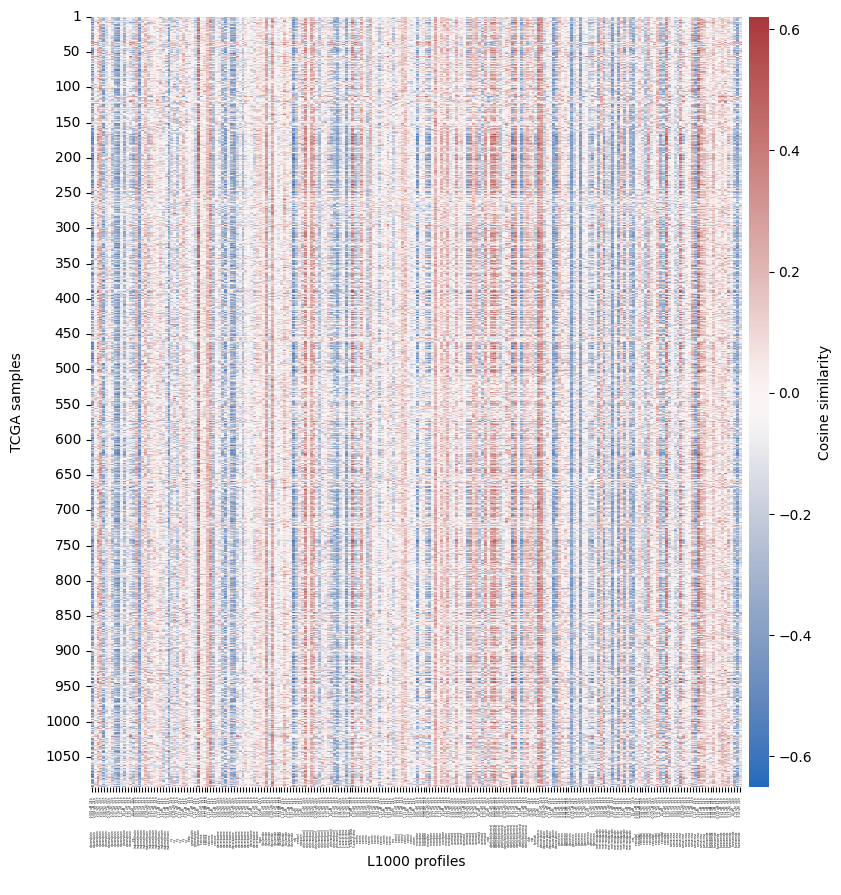

In [11]:
# Figure 5: tumours x MC signatures.
mc_labels = condition_labels("MC", names, width=25)

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(
    per_tumour["MC"], ax=ax, cmap="vlag",
    cbar_kws={"label": "Cosine similarity", "pad": 0.01, "aspect": 40},
)
ax.set_ylabel("TCGA samples\n")
ax.set_xlabel("L1000 profiles\n")
ax.set_yticks(np.arange(0, len(tumour_ids), 50) - 0.5)
ax.set_yticklabels([1] + list(range(50, len(tumour_ids), 50)), size=10)
ax.set_xticks(np.arange(len(mc_labels)) + 0.5)
ax.set_xticklabels(mc_labels, size=2, rotation=90)
for ext in ("png", "pdf"):
    plt.savefig(f"{FIGURES}/Figure-5_CS_Heatmap_TCGA_samples_vs_L1000_MC.{ext}",
                dpi=500, bbox_inches="tight")
# 220 compound labels at font size 2: the preview shows the pattern, not the
# names. See figures/Figure-5_CS_Heatmap_TCGA_samples_vs_L1000_MC.pdf.
plt.show()

In [12]:
# Table S14, and the 20 SMC conditions most similar to tumours on average.
per_tumour["MC"].set_axis(mc_labels, axis=1).to_csv(
    f"{TABLES}/Table-X_CS_Heatmap_TCGA_samples_vs_L1000_MC.csv"
)

mean_smc = per_tumour["SMC"].mean().sort_values(ascending=False)
top20 = (
    signatures["SMC"].set_index("sig_id").loc[mean_smc.index[:20],
                                              ["inchikey", "dose", "time"]]
    .assign(cosine_similarity=mean_smc.values[:20])
    .reset_index()
)
top20.insert(1, "compound_name", [names[k] for k in top20["inchikey"]])
top20.to_csv(f"{TABLES}/TOP20_SMC_indiv_cossim.csv", index=False)
top20

,index,compound_name,inchikey,dose,time,cosine_similarity
0,REP.A026_MCF7_24H:M01,fluvoxamine,CJOFXWAVKWHTFT-XSFVSMFZSA-N,3.33 uM,24 h,0.304664
1,REP.A014_MCF7_24H:I13,letrozole,HPJKCIUCZWXJDR-UHFFFAOYSA-N,2.22 uM,24 h,0.304378
2,REP.A025_MCF7_24H:D12,simvastatin,RYMZZMVNJRMUDD-HGQWONQESA-N,0.25 uM,24 h,0.296729
3,REP.A017_MCF7_24H:K16,nordihydroguaiaretic acid,HCZKYJDFEPMADG-UHFFFAOYSA-N,0.04 uM,24 h,0.288781
4,PCLB003_MCF7_24H:BRD-K85133207-001-01-1:10,fluoxetine,RTHCYVBBDHJXIQ-UHFFFAOYSA-N,2.22 uM,24 h,0.283630
5,REP.A011_MCF7_24H:K01,guanethidine,ACGDKVXYNVEAGU-UHFFFAOYSA-N,3.33 uM,24 h,0.280982
6,REP.A019_MCF7_24H:B19,ornidazole,IPWKIXLWTCNBKN-UHFFFAOYSA-N,2.22 uM,24 h,0.269157
7,PCLB003_MCF7_24H:BRD-K98109757-001-01-0:0.12,raloxifene,GZUITABIAKMVPG-UHFFFAOYSA-N,0.03 uM,24 h,0.266070
8,CPC007_MCF7_24H:BRD-K57930080-004-05-1:10,ethoxyquin,DECIPOUIJURFOJ-UHFFFAOYSA-N,10 uM,24 h,0.260116
9,REP.A018_MCF7_24H:I02,resorcinol,GHMLBKRAJCXXBS-UHFFFAOYSA-N,0.74 uM,24 h,0.253976


## 6. MC vs SMC compound signatures

A different question: independently of the tissue, do suspected carcinogens
produce responses that resemble those of known carcinogens? This is the
guilt-by-association argument of the study — Figure 3 and Table S11.

Values below `|z| = 2` are set to zero first, so the similarity is driven by
genes the compound actually moves rather than by the bulk of inert genes.

In [13]:
pairwise = pd.DataFrame(
    cosine_similarity(flatten(zscores["MC"], FLATTEN_CUTOFF), flatten(zscores["SMC"], FLATTEN_CUTOFF)),
    index=signatures["MC"]["sig_id"].values,
    columns=signatures["SMC"]["sig_id"].values,
)

# Keep only profiles involved in at least one similar pair, otherwise the
# heatmap is dominated by empty rows and columns.
pairwise = pairwise.loc[
    (pairwise > PAIR_CUTOFF).any(axis=1), (pairwise > PAIR_CUTOFF).any(axis=0)
]
print(f"{pairwise.shape[0]} MC and {pairwise.shape[1]} SMC profiles "
      f"with at least one similarity > {PAIR_CUTOFF}")

24 MC and 74 SMC profiles with at least one similarity > 0.4


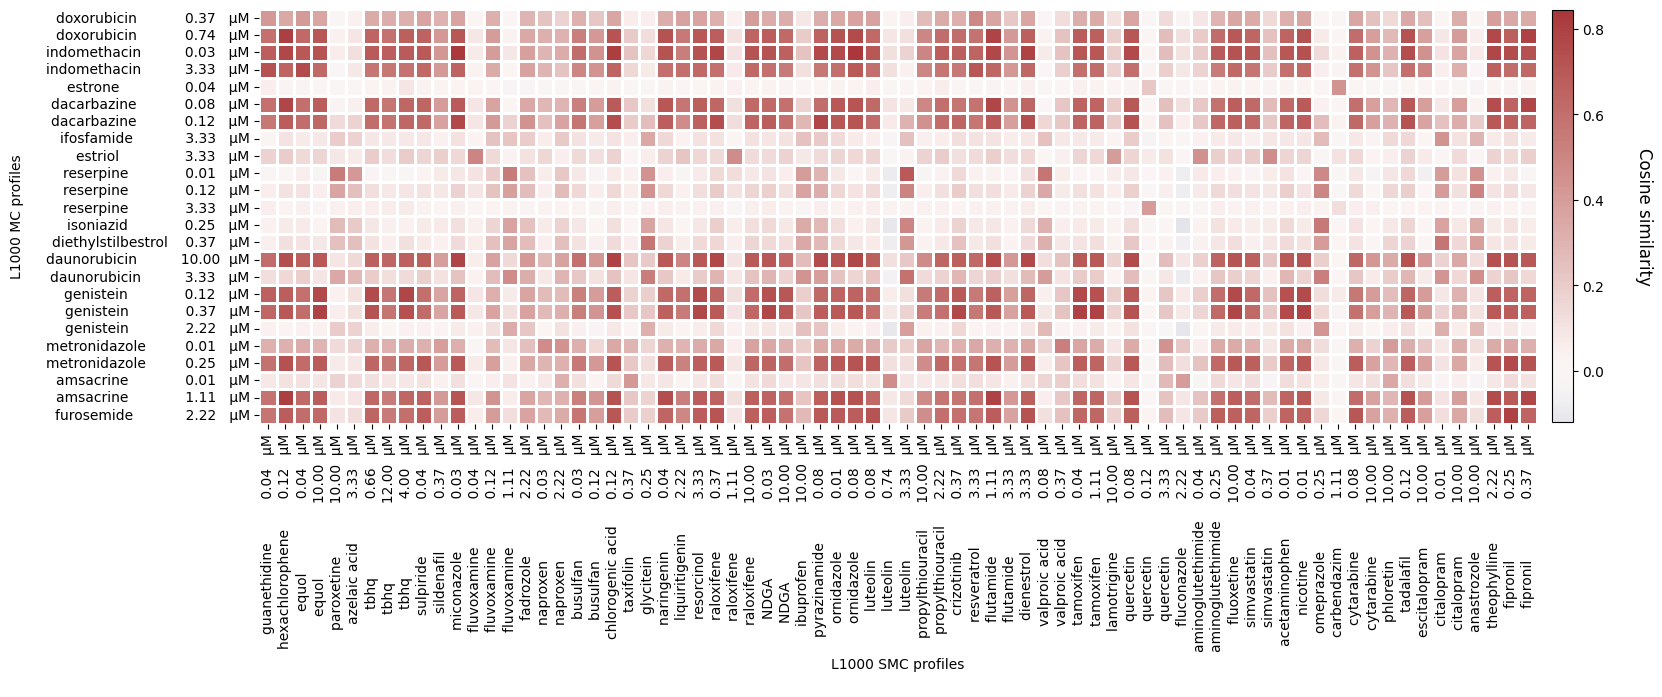

In [14]:
def dose_labels(chem_class, sig_ids, width=20):
    rows = signatures[chem_class].set_index("sig_id").loc[sig_ids]
    return [
        "{: <{w}}  {: <6.2f} µM".format(
            axis_name(names, row.inchikey), float(row.dose[:-3]), w=width
        )
        for row in rows.itertuples()
    ]


fig, ax = plt.subplots(figsize=(18, 8))
sns.heatmap(
    pairwise, ax=ax, cmap="vlag", center=0, square=True, linewidths=0.8, cbar=False,
    yticklabels=dose_labels("MC", pairwise.index),
    xticklabels=dose_labels("SMC", pairwise.columns),
)
ax.set_ylabel("L1000 MC profiles\n")
ax.set_xlabel("L1000 SMC profiles\n")
cbar = fig.colorbar(ax.collections[0], ax=ax, orientation="vertical",
                    pad=0.01, shrink=0.66)
cbar.ax.text(2, 0.5, "Cosine similarity\n\n", rotation=-90, va="center",
             ha="left", fontsize=12, transform=cbar.ax.transAxes)
fig.tight_layout()
for ext in ("png", "pdf"):
    plt.savefig(f"{FIGURES}/Figure-3_L1000_MC_SMC_cosine_similarity_heatmap.{ext}",
                dpi=500, bbox_inches="tight")
# See figures/Figure-3_L1000_MC_SMC_cosine_similarity_heatmap.pdf for a version
# where the compound and dose labels can be read.
plt.show()

In [15]:
# Table S11.
pairwise.set_axis(dose_labels("MC", pairwise.index), axis=0).set_axis(
    dose_labels("SMC", pairwise.columns), axis=1
).to_csv(f"{TABLES}/Table_SMC_MC_CS_Analysis.csv")